# Baseline CNN with training-only augmentation

Run `notebooks/01_data_preparation/01_chest_xray_train_val_test_split.ipynb` first, including its duplicate-check and manifest cell. This notebook loads the prepared `chest_xray_cnn_splits/{train,val,test}/{NORMAL,PNEUMONIA}` folders, then applies conservative random rotation, zoom, and translation to **training batches only**, following `augment_training_dataset` in `00_imbalance_utilities.ipynb`. It does not change class counts, and validation and test images are left unaugmented.

## Find prepared data and load splits

In [2]:
from pathlib import Path
import json
import subprocess
import sys
import numpy as np
import tensorflow as tf

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (parent / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from this project or set PROJECT_ROOT explicitly.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation.binary_metrics import save_training_history

RUN_ID = "seed42_run01"
TARGET_SENSITIVITY = 0.90
MANIFEST_SUMMARY = json.loads((PROJECT_ROOT / "data" / "dataset_manifest_summary.json").read_text(encoding="utf-8"))
MANIFEST_SHA256 = MANIFEST_SUMMARY["manifest_sha256"]
EXPERIMENT_NAME = "Baseline_Augmentation"
RESULTS_DIR = PROJECT_ROOT / "results" / "baseline_cnn" / RUN_ID / "augmentation"
if RESULTS_DIR.exists() and any(path.is_file() for path in RESULTS_DIR.rglob("*")):
    raise FileExistsError(f"Refusing to overwrite run outputs: {RESULTS_DIR}")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR = None  # Set explicitly if the prepared split is in another location.
if SPLIT_DIR is None:
    kagglehub_versions = (Path.home() / ".cache" / "kagglehub" / "datasets" /
                          "paultimothymooney" / "chest-xray-pneumonia" / "versions")
    candidate_dirs = [
        PROJECT_ROOT / "data" / "chest_xray_cnn_splits",
        PROJECT_ROOT / "chest_xray_cnn_splits",
        kagglehub_versions / "chest_xray_cnn_splits",
        *sorted(kagglehub_versions.glob("*/chest_xray_cnn_splits")),
    ]
else:
    candidate_dirs = [Path(SPLIT_DIR)]
data_dir = next(
    (path for path in candidate_dirs if all((path / split).is_dir() for split in ("train", "val", "test"))),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Prepared splits not found. Run notebooks/01_data_preparation/01_chest_xray_train_val_test_split.ipynb "
        "through its split and duplicate-check/manifest cells first. Checked: "
        + ", ".join(str(path) for path in candidate_dirs)
    )
subprocess.run([sys.executable, str(PROJECT_ROOT / "src" / "data" / "validate_dataset.py"), "--split-dir", str(data_dir)], check=True)
print(f"Using prepared data from: {data_dir}")

def load_split(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        data_dir / split,
        image_size=IMAGE_SIZE,
        color_mode="grayscale",
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=shuffle,
        seed=SEED if shuffle else None,
    )

train_ds = load_split("train", shuffle=True)
val_ds = load_split("val", shuffle=False)
class_names = train_ds.class_names
if class_names != ["NORMAL", "PNEUMONIA"]:
    raise ValueError(f"Expected classes ['NORMAL', 'PNEUMONIA']; got {class_names}")
if val_ds.class_names != class_names:
    raise ValueError("Train and validation folders must have matching classes.")
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
print("Class mapping:", {name: index for index, name in enumerate(class_names)})


c:\Users\apsur\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using prepared data from: C:\Users\apsur\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\chest_xray_cnn_splits
Found 4688 files belonging to 2 classes.
Found 518 files belonging to 2 classes.
Found 618 files belonging to 2 classes.
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


## Apply training-only augmentation

This mirrors the augmentation utility in `00_imbalance_utilities.ipynb`. Transforms preserve the labels and image shape. Set any factor to `0.0` to disable that transform. Validation and test datasets are not passed through the augmentation function.

In [3]:
rotation_factor = 0.02
zoom_factor = 0.05
translation_factor = 0.02

for name, value, maximum in (
    ("rotation_factor", rotation_factor, 0.5),
    ("zoom_factor", zoom_factor, 1.0),
    ("translation_factor", translation_factor, 1.0),
):
    if not 0 <= value <= maximum:
        raise ValueError(f"{name} must be between 0 and {maximum}.")

augmentation_layers = []
if rotation_factor:
    augmentation_layers.append(
        tf.keras.layers.RandomRotation(rotation_factor, fill_mode="reflect", seed=SEED)
    )
if zoom_factor:
    augmentation_layers.append(
        tf.keras.layers.RandomZoom(
            height_factor=(-zoom_factor, zoom_factor),
            width_factor=(-zoom_factor, zoom_factor),
            fill_mode="reflect",
            seed=SEED + 1,
        )
    )
if translation_factor:
    augmentation_layers.append(
        tf.keras.layers.RandomTranslation(
            height_factor=translation_factor,
            width_factor=translation_factor,
            fill_mode="reflect",
            seed=SEED + 2,
        )
    )

if augmentation_layers:
    augmenter = tf.keras.Sequential(augmentation_layers, name="train_augmenter")

    def augment_batch(images, labels):
        augmented = augmenter(images, training=True)
        augmented.set_shape(images.shape)
        return augmented, labels

    augmented_train_ds = train_ds.map(
        augment_batch, num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)
else:
    augmented_train_ds = train_ds

print(
    "Training augmentation enabled:",
    {"rotation": rotation_factor, "zoom": zoom_factor, "translation": translation_factor},
)

Training augmentation enabled: {'rotation': 0.02, 'zoom': 0.05, 'translation': 0.02}


## Build and train baseline CNN

In [4]:
tf.keras.utils.set_random_seed(SEED)
num_classes = len(class_names)
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(*IMAGE_SIZE, 1)),
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax"),
    ],
    name="baseline_cnn_augmentation",
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
history = model.fit(
    augmented_train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
)

Model: "baseline_cnn_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,058 (394.76 KB)

 Trainable params: 101,058 (394.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 139s 898ms/step - accuracy: 0.7368 - loss: 0.5691 - val_accuracy: 0.7220 - val_loss: 0.5402
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 136s 916ms/step - accuracy: 0.7372 - loss: 0.4924 - val_accuracy: 0.7394 - val_loss: 0.4912
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 134s 906ms/step - accuracy: 0.7387 - loss: 0.4683 - val_accuracy: 0.7394 - val_loss: 0.4900
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 129s 866ms/step - accuracy: 0.7425 - loss: 0.4569 - val_accuracy: 0.8050 - val_loss: 0.4475
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 66s 448ms/step - accuracy: 0.7897 - loss: 0.4157 - val_accuracy: 0.6988 - val_loss: 0.5130
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 68s 459ms/step - accuracy: 0.8270 - loss: 0.3605 - val_accuracy: 0.8494 - val_loss: 0.3327
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 68s 460ms/step - accuracy: 0.8485 - loss: 0.3252 - val_accuracy: 0.8822 - val_loss: 0.2883
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 69s 464ms/step - accuracy: 0.8573 - los

In [7]:
from pathlib import Path

model_path = PROJECT_ROOT / "models" / "baseline" / f"baseline_cnn_augmentation_{RUN_ID}.keras"
model_path.parent.mkdir(parents=True, exist_ok=True)
if model_path.exists():
    raise FileExistsError(f"Refusing to overwrite an existing checkpoint: {model_path}. Set a new filename first.")
model.save(model_path)
if not model_path.is_file() or model_path.stat().st_size == 0:
    raise IOError(f"Model save did not create a non-empty file: {model_path}")
print(f"Full Keras model saved to: {model_path.resolve()}")
save_training_history(history, RESULTS_DIR / "training_history.csv")
experiment_config = {
    "model": EXPERIMENT_NAME, "run_id": RUN_ID, "seed": SEED,
    "manifest_sha256": MANIFEST_SHA256, "target_sensitivity": TARGET_SENSITIVITY,
    "image_size": list(IMAGE_SIZE), "color_mode": "grayscale",
    "batch_size": BATCH_SIZE, "max_epochs": EPOCHS, "optimizer": "Adam",
    "learning_rate": float(tf.keras.backend.get_value(model.optimizer.learning_rate)),
    "loss": "sparse_categorical_crossentropy", "checkpoint": str(model_path.resolve()),
    "training_counts": {name: int(MANIFEST_SUMMARY["counts"]["train"][name]) for name in class_names},
    "class_weights": {str(key): float(value) for key, value in class_weights.items()} if "class_weights" in globals() else None,
    "oversampling_target_per_class": int(target_per_class) if "target_per_class" in globals() else None,
    "augmentation": {"rotation": rotation_factor, "zoom": zoom_factor, "translation": translation_factor} if "rotation_factor" in globals() else None,
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(experiment_config, indent=2) + "\n", encoding="utf-8")


Full Keras model saved to: C:\dev\Cnn\Cnn\xray-vision-pneumonia-CNN\Baseline_Cnn\baseline_cnn_augmentation.keras


## Evaluate on the held-out test set

In [5]:
print("Training and checkpoint save complete.")
print("Held-out test evaluation is deferred until all seven models are trained and validation-only model selection is complete.")
print("Run the unified evaluator from the transfer-learning notebook or with:")
print(f"python {PROJECT_ROOT / 'src' / 'evaluation' / 'evaluate_experiments.py'} --run-id {RUN_ID}")


Test loss: 0.5662
Test accuracy: 0.7201

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.8816    0.2900    0.4365       231
   PNEUMONIA     0.6974    0.9767    0.8138       387

    accuracy                         0.7201       618
   macro avg     0.7895    0.6334    0.6251       618
weighted avg     0.7663    0.7201    0.6728       618

Confusion matrix (rows=true, columns=predicted):
[[ 67 164]
 [  9 378]]


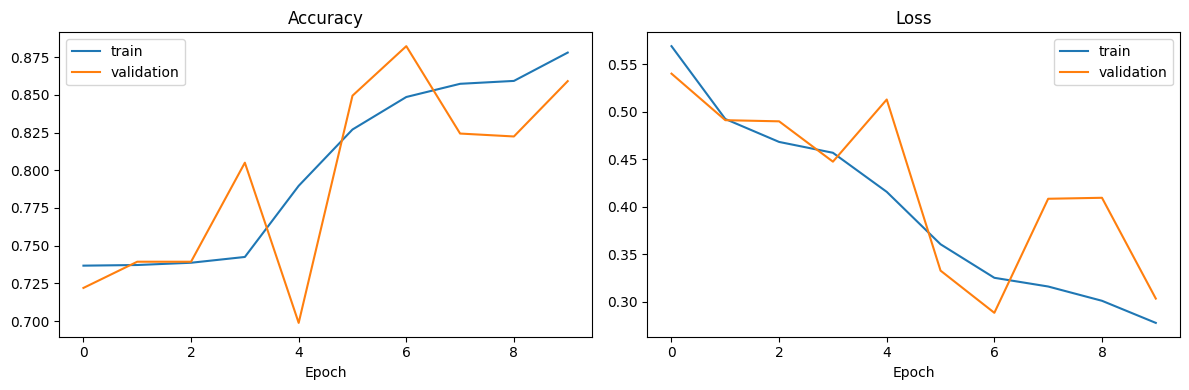

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
fig.savefig(RESULTS_DIR / "training_history.png", dpi=140)
plt.show()
